In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd

file_path = (
    "/content/drive/MyDrive/"
    "Smart-Retail-Sales-Customer-Intelligence/"
    "data/processed/retail_sales_cleaned.parquet"
)

df = pd.read_parquet(file_path)
df.shape
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SalesAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [ ]:
df['Quantity'].describe()

,Quantity
count,1.033059e+06
mean,1.007678e+01
std,1.751957e+02
min,-8.099500e+04
25%,1.000000e+00
50%,3.000000e+00
75%,1.000000e+01
max,8.099500e+04


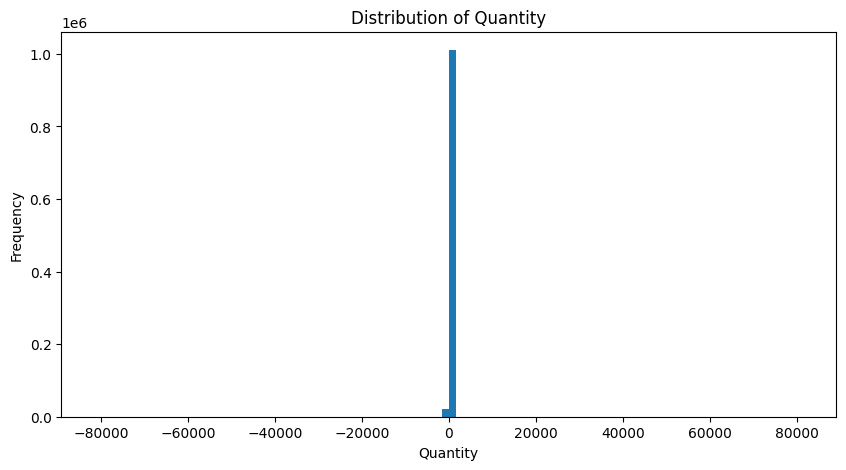

,Quantity
0.00,-80995.0
0.25,1.0
0.50,3.0
0.75,10.0
0.90,24.0
0.95,30.0
0.99,108.0
1.00,80995.0


In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.hist(df['Quantity'], bins=100)
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.title('Distribution of Quantity')
plt.show()
df["Quantity"].value_counts(bins=10).sort_index()
df["Quantity"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1])

In [ ]:
(df['Quantity']<0).sum()
(df["Invoice"].astype(str).str.startswith("C")).sum()
df[
    (df["Quantity"] < 0) &
    (~df["Invoice"].astype(str).str.startswith("C"))
]["Description"].value_counts().head(20)
df['Invoice']

,Invoice
0,489434
1,489434
2,489434
3,489434
4,489434
...,...
1033054,581587
1033055,581587
1033056,581587
1033057,581587


In [ ]:
df['Price'].describe()
(df['Price']==0).sum()
df[df["Price"]==0]["Description"].value_counts().head(20)
(df['Quantity']>1000).sum()
df[df["Quantity"]>1000]["Description"].value_counts().head(20)
df[df["Price"]>1000]["Price"].describe()
high_price = df[df["Price"] > 1000]

print(high_price.shape)
print(high_price["Price"].count())

(239, 9)
239


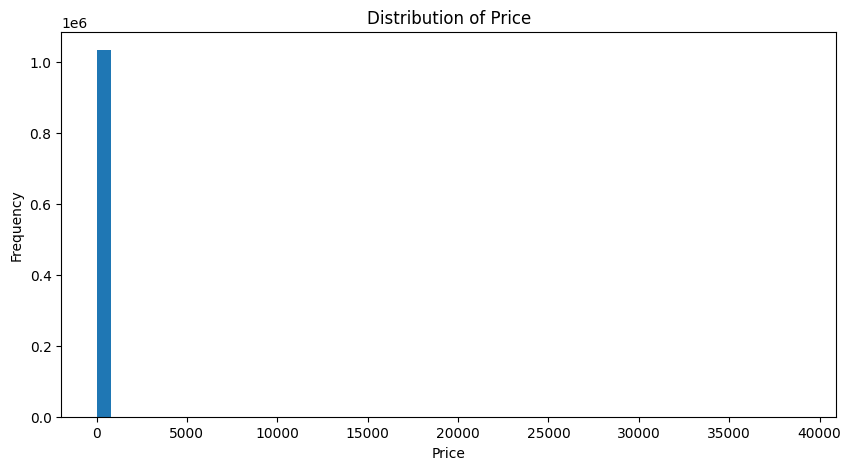

,Price
0.00,0.00
0.25,1.25
0.50,2.10
0.75,4.15
0.90,7.95
0.95,9.95
0.99,18.00
1.00,38970.00


In [ ]:
plt.figure(figsize=(10,5))
plt.hist(df['Price'], bins=50)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Distribution of Price')
plt.show()
df["Price"].value_counts(bins=10).sort_index()
df["Price"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1])

In [ ]:
df['SalesAmount'].describe()
'''print((df["Quantity"]>0).sum())
print((df["SalesAmount"]==0).sum())
print((df['SalesAmount']<0).sum())
print("Total rows:", len(df))
print("Negative:", (df["SalesAmount"] < 0).sum())
print("Zero:", (df["SalesAmount"] == 0).sum())
print("Positive:", (df["SalesAmount"] > 0).sum())
print("Missing:", df["SalesAmount"].isna().sum())'''

negative_sales=df[df['SalesAmount']<0]
negative_sales[["Invoice", "StockCode", "Description",
                "Quantity", "Price", "SalesAmount"]].head(10)
negative_sales['Invoice'] .astype(str).str.startswith("C").sum()

np.int64(19104)

In [ ]:
zero_sales = df[df["SalesAmount"] == 0]

zero_sales[["Invoice", "StockCode", "Description",
            "Quantity", "Price", "SalesAmount"]].head(10)
zero_sales = df[df["SalesAmount"] == 0]

print("Total zero SalesAmount:", len(zero_sales))
print("Price is zero:", (zero_sales["Price"] == 0).sum())
print("Quantity is zero:", (zero_sales["Quantity"] == 0).sum())
print("SalesAmount above 1000:", (df["SalesAmount"] > 1000).sum())

print("SalesAmount below -1000:", (df["SalesAmount"] < -1000).sum())

df.nlargest(10, "SalesAmount")[
    ["Invoice", "Description", "Quantity", "Price", "SalesAmount", "Country"]

]

df[df["Quantity"] > 10000][
    ["Invoice", "StockCode", "Description",
     "Quantity", "Price", "SalesAmount", "Country"]
]

high_quantity = df[df["Quantity"] > 10000]

print("Total high-quantity rows:", len(high_quantity))

print(
    "Cancellation invoices:",
    high_quantity["Invoice"].astype(str).str.startswith("C").sum()
)

high_quantity = df[df["Quantity"] > 10000]

high_quantity[
    ["Invoice", "InvoiceDate", "Customer ID",
     "Description", "Quantity", "Price", "SalesAmount"]
]

Total zero SalesAmount: 6034
Price is zero: 6034
Quantity is zero: 0
SalesAmount above 1000: 746
SalesAmount below -1000: 165
Total high-quantity rows: 9
Cancellation invoices: 0


,Invoice,InvoiceDate,Customer ID,Description,Quantity,Price,SalesAmount
89849,497946,2010-02-15 11:57:00,13902.0,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2
125789,501534,2010-03-17 13:09:00,13902.0,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0
125790,501534,2010-03-17 13:09:00,13902.0,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0
125791,501534,2010-03-17 13:09:00,13902.0,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0
125792,501534,2010-03-17 13:09:00,13902.0,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4
189991,507637,2010-05-10 14:55:00,NaN,FLAG OF ST GEORGE CAR FLAG,10200,0.00,0.0
557425,541431,2011-01-18 10:01:00,12346.0,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6
993811,578841,2011-11-25 15:57:00,13256.0,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,0.0
1031577,581483,2011-12-09 09:15:00,16446.0,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6


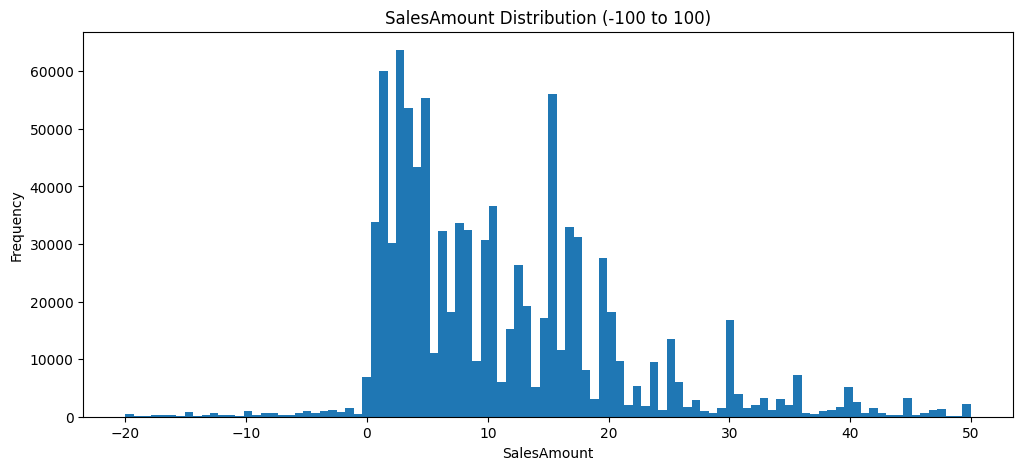

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(df["SalesAmount"], bins=100, range=(-20, 50))

plt.title("SalesAmount Distribution (-100 to 100)")
plt.xlabel("SalesAmount")
plt.ylabel("Frequency")

plt.show()


In [5]:
sales_quantiles = df["SalesAmount"].quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
)

print(sales_quantiles)
Q1 = df["SalesAmount"].quantile(0.25)
Q3 = df["SalesAmount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Identify potential outliers
outliers = df[
    (df["SalesAmount"] < lower_bound) |
    (df["SalesAmount"] > upper_bound)
]

print("Total rows:", len(df))
print("Potential outliers:", len(outliers))

print(
    "Percentage of potential outliers:",
    round((len(outliers) / len(df)) * 100, 2),
    "%"
)

0.00   -168469.60
0.25         3.75
0.50         9.92
0.75        17.70
0.90        32.96
0.95        59.80
0.99       182.88
1.00    168469.60
Name: SalesAmount, dtype: float64
Q1: 3.75
Q3: 17.700000000000003
IQR: 13.950000000000003
Lower Bound: -17.175000000000004
Upper Bound: 38.62500000000001
Total rows: 1033059
Potential outliers: 89003
Percentage of potential outliers: 8.62 %


In [7]:
lower_outliers = df[df["SalesAmount"] < lower_bound]

upper_outliers = df[df["SalesAmount"] > upper_bound]

print("Lower outliers:", len(lower_outliers))
print("Upper outliers:", len(upper_outliers))

print(
    "Negative SalesAmount in lower outliers:",
    (lower_outliers["SalesAmount"] < 0).sum()
)

print(
    "Positive SalesAmount in upper outliers:",
    (upper_outliers["SalesAmount"] > 0).sum()
)

upper_outliers[
    ["Invoice", "Description", "Quantity",
     "Price", "SalesAmount", "Country"]
].sort_values(
    by="SalesAmount",
    ascending=False
).head(10)

Lower outliers: 5090
Upper outliers: 83913
Negative SalesAmount in lower outliers: 5090
Positive SalesAmount in upper outliers: 83913


,Invoice,Description,Quantity,Price,SalesAmount,Country
1031577,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
557425,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
717235,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
238928,512771,Manual,1,25111.09,25111.09,United Kingdom
426968,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,United Kingdom
511148,537632,AMAZON FEE,1,13541.33,13541.33,United Kingdom
794064,A563185,Adjust bad debt,1,11062.06,11062.06,United Kingdom
133501,502265,Manual,1,10953.50,10953.50,United Kingdom
133499,502263,Manual,1,10953.50,10953.50,United Kingdom
368449,525399,Manual,1,10468.80,10468.80,United Kingdom


In [9]:
# Check non-standard descriptions
keywords = ["MANUAL", "AMAZON FEE", "ADJUST BAD DEBT"]

for keyword in keywords:
    result = df[
        df["Description"].str.contains(
            keyword, case=False, na=False
        )
    ]

    print(f"\n{keyword}")
    print("Rows:", len(result))
    print("Total SalesAmount:", result["SalesAmount"].sum())

    manual_rows = df[
    df["Description"].str.contains(
        "MANUAL", case=False, na=False
    )
]

manual_rows[
    ["Invoice", "Description", "Quantity",
     "Price", "SalesAmount", "Country"]
].head(10)


MANUAL
Rows: 1392
Total SalesAmount: -83311.28

AMAZON FEE
Rows: 36
Total SalesAmount: -221520.5

ADJUST BAD DEBT
Rows: 1
Total SalesAmount: 11062.06


,Invoice,Description,Quantity,Price,SalesAmount,Country
2661,489609,Manual,1,4.00,4.00,United Kingdom
3016,C489651,Manual,-1,5.10,-5.10,United Kingdom
5826,C489859,Manual,-1,69.57,-69.57,United Kingdom
9168,C490126,Manual,-1,5.95,-5.95,United Kingdom
9215,C490129,Manual,-1,1998.49,-1998.49,United Kingdom
11193,490300,Manual,1,0.85,0.85,United Kingdom
11194,490300,Manual,1,0.21,0.21,United Kingdom
15906,490727,Manual,1,0.00,0.00,United Kingdom
17072,C490748,Manual,-1,309.73,-309.73,United Kingdom
17185,490760,Manual,1,10.00,10.00,United Kingdom


In [11]:
manual_rows = df[
    df["Description"].str.contains(
        "MANUAL", case=False, na=False
    )
]

print("Total MANUAL rows:", len(manual_rows))

print("\nQuantity sign:")
print(
    manual_rows["Quantity"]
    .apply(lambda x: "Positive" if x > 0 else "Negative" if x < 0 else "Zero")
    .value_counts()
)

print("\nSalesAmount sign:")
print(
    manual_rows["SalesAmount"]
    .apply(lambda x: "Positive" if x > 0 else "Negative" if x < 0 else "Zero")
    .value_counts()
)

manual_rows["Invoice"] = manual_rows["Invoice"].astype(str)

print(
    "Invoice starts with C:"
)
print(
    manual_rows["Invoice"]
    .str.startswith("C")
    .value_counts()
)

Total MANUAL rows: 1392

Quantity sign:
Quantity
Positive    859
Negative    533
Name: count, dtype: int64

SalesAmount sign:
SalesAmount
Positive    852
Negative    533
Zero          7
Name: count, dtype: int64
Invoice starts with C:
Invoice
False    858
True     534
Name: count, dtype: int64


/tmp/ipykernel_2475/366398616.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  manual_rows["Invoice"] = manual_rows["Invoice"].astype(str)


In [12]:
manual_rows[
    manual_rows["Invoice"].str.startswith("C")
    != (manual_rows["Quantity"] < 0)
][
    ["Invoice", "Description", "Quantity",
     "Price", "SalesAmount", "Country"]
]

,Invoice,Description,Quantity,Price,SalesAmount,Country
75972,C496350,Manual,1,373.57,373.57,United Kingdom
